In [4]:
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

np.random.seed(42)
ZIP_PATH = "/content/TEAM_5.zip"

DIGITS = [0, 1, 3]
K = 3
PATCH_SIZE = 7
MAX_ITER = 20
TOL = 1e-5
VAR_FLOOR = 1e-4

### Load Images

In [11]:
def load_images(z, split, digits):
    images, labels, paths = [], [], []

    for digit in digits:
        folder = f"TEAM_5/{split}/{digit}/"

        files = sorted(
            name for name in z.namelist()
            if name.startswith(folder)
            and name.lower().endswith(".png")
        )

        for filename in files:
            image = Image.open(
                BytesIO(z.read(filename))
            ).convert("L").resize((28, 28))

            image = np.asarray(image, dtype=np.float32) / 255.0

            images.append(image)
            labels.append(digit)
            paths.append(filename)

    return np.asarray(images), np.asarray(labels), paths


with zipfile.ZipFile(ZIP_PATH, "r") as z:
    train_images, y_train, train_paths = load_images(
        z, "train", DIGITS
    )
    dev_images, y_dev, dev_paths = load_images(
        z, "dev", DIGITS
    )
    test_images, y_test, test_paths = load_images(
        z, "test", DIGITS
    )

print("Training images:", len(train_images))
print("Development images:", len(dev_images))
print("Testing images:", len(test_images))

Training images: 15004
Development images: 3792
Testing images: 3125


### Split each images into patches

In [12]:
def extract_patches(images):
    patches = np.zeros(
        (len(images), 16, PATCH_SIZE * PATCH_SIZE),
        dtype=np.float32
    )

    for i, image in enumerate(images):
        p = 0

        for r in range(0, 28, PATCH_SIZE):
            for c in range(0, 28, PATCH_SIZE):
                patches[i, p] = image[
                    r:r + PATCH_SIZE,
                    c:c + PATCH_SIZE
                ].reshape(-1)

                p += 1

    return patches


train_patches = extract_patches(train_images)
dev_patches = extract_patches(dev_images)
test_patches = extract_patches(test_images)

print("Patches per image:", train_patches.shape[1])
print("Features per patch:", train_patches.shape[2])


Patches per image: 16
Features per patch: 49


### Guassian log density
$$
\ln\mathcal N(\mathbf x\mid\boldsymbol\mu,\boldsymbol\Sigma)
=
-\frac12\left[
D\ln(2\pi)
+\sum_{d=1}^{D}\ln\sigma_d^2
+\sum_{d=1}^{D}
\frac{(x_d-\mu_d)^2}{\sigma_d^2}
\right]
$$

In [13]:
def log_gaussian(X, mean, variance):
    D = X.shape[1]

    # Ensure every feature variance is at least VAR_FLOOR
    variance = np.maximum(variance, VAR_FLOOR)

    diff = X - mean

    return -0.5 * (
        D * np.log(2 * np.pi)
        + np.sum(np.log(variance))
        + np.sum((diff ** 2) / variance, axis=1)
    )


def log_sum_exp(values):
    maximum = np.max(values, axis=1, keepdims=True)

    return maximum[:, 0] + np.log(
        np.sum(np.exp(values - maximum), axis=1)
    )

### EM Algorithm


1.   Initialize means, variances and weights
2.   E-step: Calculate responsibilities
$$
\gamma_{nk} = \frac{\pi_k \mathcal N(\mathbf x_n \mid \boldsymbol\mu_k, \sigma_k^2 \mathbf I)}{\sum_j \pi_j \mathcal N(\mathbf x_n \mid \boldsymbol\mu_j, \sigma_j^2 \mathbf I)}
$$
3.   M-step: Update weights, means and variances
$$
N_k = \sum_{n=1}^{N} \gamma_{nk}
$$

$$
\pi_k = \frac{N_k}{N}
$$

$$
\boldsymbol\mu_k = \frac{1}{N_k} \sum_{n=1}^{N} \gamma_{nk} \mathbf x_n
$$

$$
\sigma_k^2 = \frac{1}{D N_k} \sum_{n=1}^{N} \gamma_{nk} \|\mathbf x_n - \boldsymbol\mu_k\|^2
$$

4.   Recalculate likelihood using updated parameters

$$
\mathcal L(\theta) = \sum_{n=1}^{N} \ln p(\mathbf x_n \mid \theta)
$$


In [14]:
def GMM(X, K):
    N, D = X.shape

    # Initialize component means from training patches
    indices = np.random.choice(N, K, replace=False)
    means = X[indices].copy()

    initial_variance = np.var(X, axis=0)

    variances = np.tile(
    np.maximum(initial_variance, VAR_FLOOR),
    (K, 1)
    )
    weights = np.ones(K) / K

    previous_likelihood = -np.inf

    for iteration in range(MAX_ITER):

        # ---------------- E-STEP ----------------
        log_p = np.zeros((N, K))

        for k in range(K):
            log_p[:, k] = (
                np.log(max(weights[k], 1e-12))
                + log_gaussian(X, means[k], variances[k])
            )

        log_total = log_sum_exp(log_p)
        responsibilities = np.exp(log_p - log_total[:, None])

        # ---------------- M-STEP ----------------
        Nk = np.maximum(
            responsibilities.sum(axis=0), 1e-12
        )

        # Update mixture weights
        weights = Nk / N

        # Update means
        means = (responsibilities.T @ X) / Nk[:, None]

        # Update isotropic variances
        for k in range(K):
            diff = X - means[k]

            variances[k] = np.maximum(
                np.sum(
                responsibilities[:, k, None] * (diff ** 2),
                axis=0
                ) / Nk[k],
                VAR_FLOOR
            )

        # Evaluate likelihood using updated parameters
        new_log_p = np.zeros((N, K))

        for k in range(K):
            new_log_p[:, k] = (
                np.log(max(weights[k], 1e-12))
                + log_gaussian(X, means[k], variances[k])
            )

        likelihood = np.sum(log_sum_exp(new_log_p))

        if np.isfinite(previous_likelihood):
            if abs(likelihood - previous_likelihood) < (
                TOL * (1 + abs(previous_likelihood))
            ):
                break

        previous_likelihood = likelihood

    return weights, means, variances

### Training GMM

In [15]:
models = {}

for digit in DIGITS:
    digit_data = train_patches[y_train == digit]

    print(f"\nTraining digit {digit}...")

    for position in range(16):
        X = digit_data[:, position, :]

        models[(digit, position)] = GMM(X, K)

    print(f"Completed digit {digit}: 16 patch GMMs")


Training digit 0...
Completed digit 0: 16 patch GMMs

Training digit 1...
Completed digit 1: 16 patch GMMs

Training digit 3...
Completed digit 3: 16 patch GMMs


### Score

In [16]:
def GMM_log_probability(X, model):
    weights, means, variances = model

    log_p = np.zeros((len(X), len(weights)))

    for k in range(len(weights)):
        log_p[:, k] = (
            np.log(max(weights[k], 1e-12))
            + log_gaussian(X, means[k], variances[k])
        )

    return log_sum_exp(log_p)

### Classify Images

In [17]:
def classify_images(patches):
    scores = np.zeros((len(patches), len(DIGITS)))

    for j, digit in enumerate(DIGITS):
        for position in range(16):
            scores[:, j] += GMM_log_probability(
                patches[:, position, :],
                models[(digit, position)]
            )

    predicted = np.asarray(DIGITS)[np.argmax(scores, axis=1)]

    return predicted, scores


### Evaluation

In [18]:
dev_predicted, dev_scores = classify_images(dev_patches)

print(
    "\nDevelopment accuracy:",
    round(np.mean(dev_predicted == y_dev) * 100, 2),
    "%"
)

test_predicted, test_scores = classify_images(test_patches)

correct = np.sum(test_predicted == y_test)
total = len(y_test)
accuracy = 100 * correct / total

print("\nTEST RESULTS")
print("Correct predictions:", correct)
print("Total test images:", total)
print("Test accuracy:", round(accuracy, 2), "%")


Development accuracy: 94.91 %

TEST RESULTS
Correct predictions: 3017
Total test images: 3125
Test accuracy: 96.54 %


### Confusion Matrix


Confusion Matrix:
[[ 941    0   39]
 [   3 1086   46]
 [  19    1  990]]


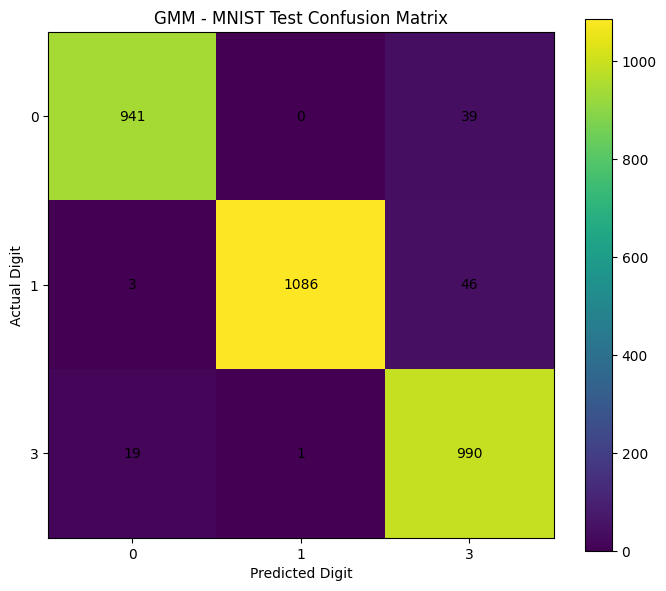


Per-digit accuracy:
Digit 0: 941/980 = 96.02%
Digit 1: 1086/1135 = 95.68%
Digit 3: 990/1010 = 98.02%


In [19]:
cm = np.zeros((len(DIGITS), len(DIGITS)), dtype=int)

for actual, predicted in zip(y_test, test_predicted):
    i = DIGITS.index(actual)
    j = DIGITS.index(predicted)
    cm[i, j] += 1

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest")
plt.xticks(range(3), DIGITS)
plt.yticks(range(3), DIGITS)
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("GMM - MNIST Test Confusion Matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()


# Per-digit accuracy
print("\nPer-digit accuracy:")

for i, digit in enumerate(DIGITS):
    count = cm[i].sum()
    print(
        f"Digit {digit}: {cm[i, i]}/{count} "
        f"= {100 * cm[i, i] / count:.2f}%"
    )

### Error Analysis


Misclassified images: 108
Actual 0 predicted as 3: 39
Actual 1 predicted as 0: 3
Actual 1 predicted as 3: 46
Actual 3 predicted as 0: 19
Actual 3 predicted as 1: 1


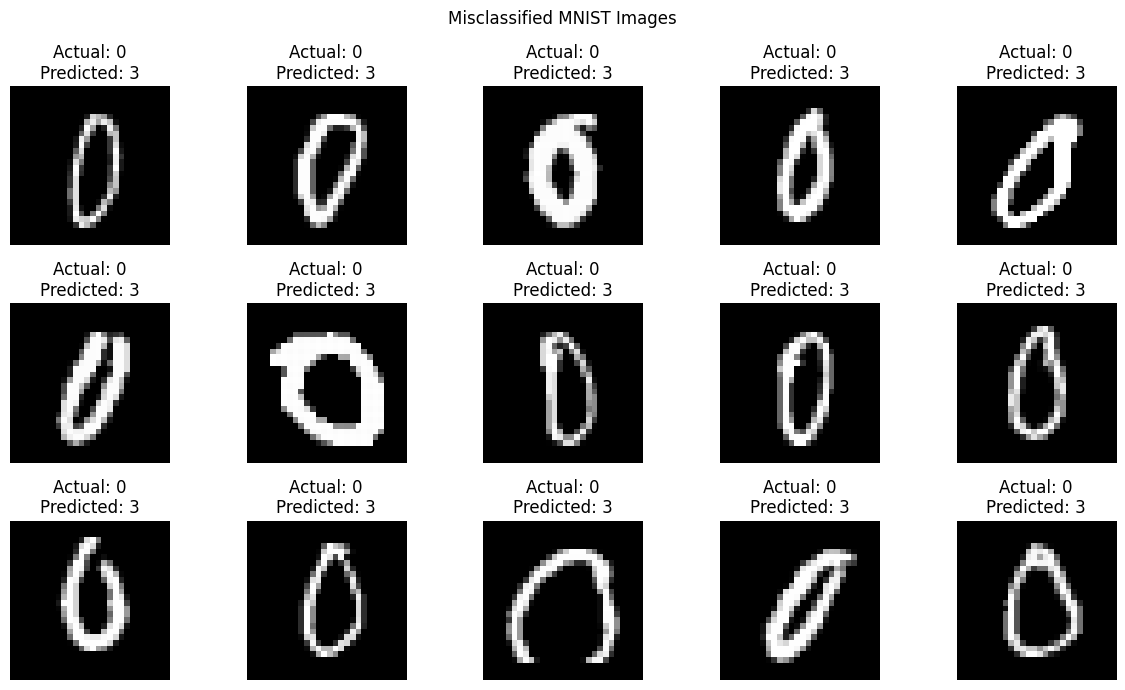

In [20]:
wrong = np.where(test_predicted != y_test)[0]

print("\nMisclassified images:", len(wrong))

for actual_digit in DIGITS:
    for predicted_digit in DIGITS:
        if actual_digit != predicted_digit:
            count = np.sum(
                (y_test == actual_digit)
                & (test_predicted == predicted_digit)
            )

            if count > 0:
                print(
                    f"Actual {actual_digit} predicted as "
                    f"{predicted_digit}: {count}"
                )


# Display up to 15 misclassified images
number_to_show = min(15, len(wrong))

if number_to_show > 0:
    plt.figure(figsize=(12, 7))

    for plot_index, sample_index in enumerate(wrong[:number_to_show]):
        plt.subplot(3, 5, plot_index + 1)
        plt.imshow(test_images[sample_index], cmap="gray")

        plt.title(
            f"Actual: {y_test[sample_index]}\n"
            f"Predicted: {test_predicted[sample_index]}"
        )
        plt.axis("off")

    plt.suptitle("Misclassified MNIST Images")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images.")


### Score Analysis for misclassified digit

Digit 1 misclassified as digit 3: 46

Comparing total log-likelihood scores:

Test image index: 988
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): 1752.6004
Score for digit 3 (S3): 1834.6840
Score difference (S3 - S1): 82.0837

Test image index: 1054
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): 278.1623
Score for digit 3 (S3): 1722.5056
Score difference (S3 - S1): 1444.3433

Test image index: 1097
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): -4161.1678
Score for digit 3 (S3): -4001.0834
Score difference (S3 - S1): 160.0844

Test image index: 1105
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): 1629.2114
Score for digit 3 (S3): 1757.3951
Score difference (S3 - S1): 128.1838

Test image index: 1160
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): -1081.9132
Score for digit 3 (S3): -487.0575
Score difference (S3 - S1): 594.8557

Test image index: 1175
Actual digit: 1
Predicted digit: 3
Score for digit 1 (S1): 1633.2747
Score for

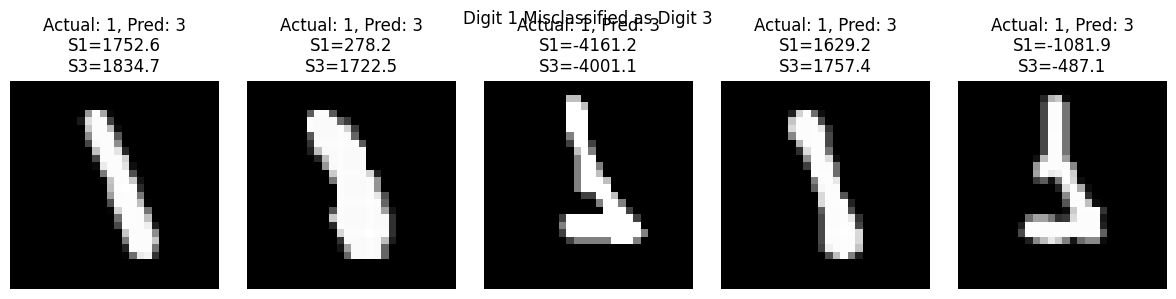

In [21]:
# Find images whose actual digit is 1 but predicted digit is 3
wrong_1_as_3 = np.where(
    (y_test == 1) & (test_predicted == 3)
)[0]

print("Digit 1 misclassified as digit 3:", len(wrong_1_as_3))

# DIGITS = [0, 1, 3]
# Therefore, score column 1 corresponds to digit 1
# and score column 2 corresponds to digit 3.

print("\nComparing total log-likelihood scores:")

for idx in wrong_1_as_3[:10]:
    score_1 = test_scores[idx, 1]
    score_3 = test_scores[idx, 2]
    margin = score_3 - score_1

    print(f"\nTest image index: {idx}")
    print(f"Actual digit: {y_test[idx]}")
    print(f"Predicted digit: {test_predicted[idx]}")
    print(f"Score for digit 1 (S1): {score_1:.4f}")
    print(f"Score for digit 3 (S3): {score_3:.4f}")
    print(f"Score difference (S3 - S1): {margin:.4f}")

# Display a few examples with their scores
number_to_show = min(5, len(wrong_1_as_3))

if number_to_show > 0:
    plt.figure(figsize=(12, 3))

    for j, idx in enumerate(wrong_1_as_3[:number_to_show]):
        plt.subplot(1, number_to_show, j + 1)
        plt.imshow(test_images[idx], cmap="gray")
        plt.title(
            f"Actual: 1, Pred: 3\n"
            f"S1={test_scores[idx, 1]:.1f}\n"
            f"S3={test_scores[idx, 2]:.1f}"
        )
        plt.axis("off")

    plt.suptitle("Digit 1 Misclassified as Digit 3")
    plt.tight_layout()
    plt.show()
